In [98]:
import pandas as pd
import numpy as np
import warnings
import networkx as nx
import glob
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image
import timm
import h5py
import io


In [115]:
dataset = pd.read_csv('../data/multi-class/insect/metadata.tsv', sep='\t')
dataset.head()

,sampleid,processid,uri,name,phylum,class,order,family,subfamily,tribe,...,large_insect_order,medium_insect_order,small_insect_order,chunk_number,copyright_license,copyright_holder,copyright_institution,copyright_contact,photographer,author
0,BIOUG70015-D01,GMCNA4897-21,BOLD:AAA0038,Lepidoptera,Arthropoda,Insecta,Lepidoptera,not_classified,not_classified,not_classified,...,train,train,train,1,Creative Commons-Attribution Non-Commercial Sh...,CBG Photography Group,Centre for Biodiversity Genomics (email:CBGIma...,collectionsBIO@gmail.com,CBG Robotic Imager,Zahra Gharaee
1,BIOUG76589-E09,CRTOA22141-21,BOLD:AAA0107,Lepidoptera,Arthropoda,Insecta,Lepidoptera,not_classified,not_classified,not_classified,...,validation,validation,validation,1,Creative Commons-Attribution Non-Commercial Sh...,CBG Photography Group,Centre for Biodiversity Genomics (email:CBGIma...,collectionsBIO@gmail.com,CBG Robotic Imager,Zahra Gharaee
2,BIOUG66193-C11,GMMVA9945-21,BOLD:AAA0293,Lepidoptera,Arthropoda,Insecta,Lepidoptera,not_classified,not_classified,not_classified,...,train,train,train,1,Creative Commons-Attribution Non-Commercial Sh...,CBG Photography Group,Centre for Biodiversity Genomics (email:CBGIma...,collectionsBIO@gmail.com,CBG Robotic Imager,Zahra Gharaee
3,BIOUG53275-A03,PLLBM1874-20,BOLD:AAA0921,Lepidoptera,Arthropoda,Insecta,Lepidoptera,not_classified,not_classified,not_classified,...,train,train,train,1,Creative Commons-Attribution Non-Commercial Sh...,CBG Photography Group,Centre for Biodiversity Genomics (email:CBGIma...,collectionsBIO@gmail.com,CBG Robotic Imager,Zahra Gharaee
4,BIOUG70131-C09,GMCNA34470-21,BOLD:AAA0937,Lepidoptera,Arthropoda,Insecta,Lepidoptera,not_classified,not_classified,not_classified,...,train,train,train,1,Creative Commons-Attribution Non-Commercial Sh...,CBG Photography Group,Centre for Biodiversity Genomics (email:CBGIma...,collectionsBIO@gmail.com,CBG Robotic Imager,Zahra Gharaee


In [119]:
dataset.columns

Index(['sampleid', 'processid', 'uri', 'name', 'phylum', 'class', 'order',
       'family', 'subfamily', 'tribe', 'genus', 'species', 'subspecies',
       'nucraw', 'image_file', 'large_diptera_family', 'medium_diptera_family',
       'small_diptera_family', 'large_insect_order', 'medium_insect_order',
       'small_insect_order', 'chunk_number', 'copyright_license',
       'copyright_holder', 'copyright_institution', 'copyright_contact',
       'photographer', 'author'],
      dtype='str')

In [120]:
dataset[['phylum', 'class', 'order',
       'family', 'subfamily', 'tribe', 'genus', 'species', 'subspecies',
       'nucraw', 'image_file']]

,phylum,class,order,family,subfamily,tribe,genus,species,subspecies,nucraw,image_file
0,Arthropoda,Insecta,Lepidoptera,not_classified,not_classified,not_classified,not_classified,not_classified,not_classified,ATTATATTTTATTTTTGGTATTTGATCAGGAATAATTGGTACCTCT...,5411755.jpg
1,Arthropoda,Insecta,Lepidoptera,not_classified,not_classified,not_classified,not_classified,not_classified,not_classified,TTTATATTTTATTTTTGGAATTTGAGCAGGCTTAGTAGGAACTTCT...,6118491.jpg
2,Arthropoda,Insecta,Lepidoptera,not_classified,not_classified,not_classified,not_classified,not_classified,not_classified,TTTATATTTTATTTTCGGTATTTGAGCTGGAATATTAGGAACTTCT...,5249245.jpg
3,Arthropoda,Insecta,Lepidoptera,not_classified,not_classified,not_classified,not_classified,not_classified,not_classified,TTTGGAATTTGAGCCGGAATAGTTGGAACTTCATTAAGATTATTAA...,3817837.jpg
4,Arthropoda,Insecta,Lepidoptera,not_classified,not_classified,not_classified,not_classified,not_classified,not_classified,ATTATATTTTATTTTTGGTATTTGAGCAGGAATAGTAGGAACTTCT...,5517537.jpg
...,...,...,...,...,...,...,...,...,...,...,...
1128308,Arthropoda,Insecta,Diptera,Phoridae,not_classified,not_classified,not_classified,not_classified,not_classified,TCTTTATTTCATTTTTGGAGCTTGAGCCGGTATAATTGGAACTTCA...,BIOUG72532-F08.jpg
1128309,Arthropoda,Insecta,Hymenoptera,Bethylidae,not_classified,not_classified,not_classified,not_classified,not_classified,TACTCTATTTTATTTTTGGTATATGAGCAGGAATAATAGGATCCTC...,BIOUG79018-F03.jpg
1128310,Arthropoda,Insecta,Hymenoptera,Agaonidae,not_classified,not_classified,not_classified,not_classified,not_classified,ATTTAATTTTTGGTATTTGATCTGGTTTAGTTGGTTTATCAATATC...,BIOUG67960-E02.jpg
1128311,Arthropoda,Insecta,Diptera,Ceratopogonidae,not_classified,not_classified,not_classified,not_classified,not_classified,TTATATTTTATTTTTGGTGCCTGATCAGGAATAGTGGGAACCTCCT...,BIOUG67113-H01.jpg


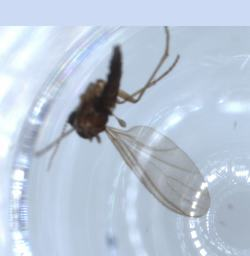

In [ ]:
hdf5 = h5py.File('../data/multi-class/insect/cropped_256.hdf5', 'r')
group_name = "bioscan_dataset"

if group_name in hdf5.keys():
    hdf5 = hdf5[group_name]

filenames = [k for k in hdf5.keys()]

data = np.asarray(hdf5[filenames[2]])
image = Image.fromarray(data)
# data = np.array(hdf5[image_name])
image = Image.open(io.BytesIO(data))
image


In [114]:
filenames

['3652473.jpg',
 '3652483.jpg',
 '3652486.jpg',
 '3652494.jpg',
 '3652523.jpg',
 '3652532.jpg',
 '3652538.jpg',
 '3652552.jpg',
 '3652566.jpg',
 '3652592.jpg',
 '3652597.jpg',
 '3652620.jpg',
 '3652638.jpg',
 '3652654.jpg',
 '3652660.jpg',
 '3652666.jpg',
 '3652674.jpg',
 '3652675.jpg',
 '3652679.jpg',
 '3652681.jpg',
 '3652689.jpg',
 '3652699.jpg',
 '3652700.jpg',
 '3652705.jpg',
 '3652712.jpg',
 '3652722.jpg',
 '3652730.jpg',
 '3652734.jpg',
 '3652745.jpg',
 '3652755.jpg',
 '3652756.jpg',
 '3652770.jpg',
 '3652773.jpg',
 '3652783.jpg',
 '3652787.jpg',
 '3652789.jpg',
 '3652814.jpg',
 '3652835.jpg',
 '3652847.jpg',
 '3652849.jpg',
 '3652850.jpg',
 '3652863.jpg',
 '3652872.jpg',
 '3652883.jpg',
 '3652901.jpg',
 '3652904.jpg',
 '3652907.jpg',
 '3652913.jpg',
 '3652914.jpg',
 '3652961.jpg',
 '3652973.jpg',
 '3652976.jpg',
 '3653001.jpg',
 '3653123.jpg',
 '3653142.jpg',
 '3653151.jpg',
 '3653155.jpg',
 '3653157.jpg',
 '3653177.jpg',
 '3653181.jpg',
 '3653200.jpg',
 '3653203.jpg',
 '365320

In [113]:
len(filenames)

1128312

In [75]:
paths = glob.glob('../data/multi-class/zooid/**/*.jpg', recursive=True)
labels = ['.'.join(dir_.split('/zooid/')[-1].split('/')[:-1]).replace(' ', '_') for dir_ in paths]

In [ ]:
model_plankton = timm.create_model(
    'hf_hub:Jookare/plankton_vit_large_patch16_224.mae', 
    pretrained=True, 
    num_classes=0
)
model_plankton.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

image = Image.open(paths[0]).convert('RGB')

In [88]:
embeddings = []

for path in paths:
    image = Image.open(paths[0]).convert('RGB')

    x = transform(image).unsqueeze(0)
    with torch.no_grad(): # Desativa o cálculo de gradientes
        features_plankton = model_plankton(x)
        embeddings.extend(features_plankton.tolist())
    
embeddings

[[0.13995885848999023,
  -0.05522964894771576,
  -0.0066216313280165195,
  0.19403859972953796,
  0.09833700209856033,
  0.0402677021920681,
  0.09643731266260147,
  0.03349149972200394,
  0.09088060259819031,
  0.05725855007767677,
  0.08717793971300125,
  0.14577586948871613,
  0.15717780590057373,
  0.014434914104640484,
  0.029058974236249924,
  0.11740221828222275,
  -0.0013209279859438539,
  0.049099911004304886,
  0.056999679654836655,
  -0.03337358310818672,
  0.04770146682858467,
  -0.05578671768307686,
  0.059907905757427216,
  -0.0952034443616867,
  0.05486046150326729,
  -0.12400274723768234,
  -0.06652090698480606,
  -0.05284601077437401,
  0.1379353404045105,
  0.011759670451283455,
  -0.05245169252157211,
  0.061533283442258835,
  0.040908996015787125,
  0.046194300055503845,
  0.0312297735363245,
  0.02498805709183216,
  0.024212243035435677,
  -0.013108361512422562,
  0.15991130471229553,
  0.012403612025082111,
  0.08367075771093369,
  -0.029781626537442207,
  0.19419

In [89]:
dataset = pd.DataFrame({
    'id': range(1, len(embeddings) + 1),
    'embeddings': embeddings,
    'label': labels
})
dataset.head()

,id,embeddings,label
0,1,"[0.13995885848999023, -0.05522964894771576, -0...",Phylum_Chordata.Subphylum_Vertebrata.Class_Ost...
1,2,"[0.13995885848999023, -0.05522964894771576, -0...",Phylum_Chordata.Subphylum_Vertebrata.Class_Ost...
2,3,"[0.13995885848999023, -0.05522964894771576, -0...",Phylum_Chordata.Subphylum_Vertebrata.Class_Ost...
3,4,"[0.13995885848999023, -0.05522964894771576, -0...",Phylum_Chordata.Subphylum_Vertebrata.Class_Ost...
4,5,"[0.13995885848999023, -0.05522964894771576, -0...",Phylum_Chordata.Subphylum_Vertebrata.Class_Ost...


In [90]:
dataset.to_parquet('../data/multi-class/zooid/full.parquet', engine='pyarrow')

In [ ]:
datasets_metadata = [
    {
        'name': 'amazon',
        'total_size': 15035,
        'train_size': 5035,
        'test_size': 10000,
        'features': 768,
        'total_classes': 351,
        'total_levels': 3,
    },
    # { O BRALEG TEM MUITO PROBLEMA DE BALANCEAMENTO
    #     'name': 'braleg',
    #     'total_size': 7575,
    #     'train_size': ,
    #     'test_size': ,
    #     'features': ,
    #     'total_classes': 277,
    #     'total_levels': 5,
    # },
]

In [36]:
features = pd.read_csv('../data/multi-class/fma/fma_metadata/features.csv', index_col=0, header=[0, 1, 2])
genres = pd.read_csv('../data/multi-class/fma/fma_metadata/genres.csv', index_col=0)
tracks = pd.read_csv('../data/multi-class/fma/fma_metadata/tracks.csv', index_col=0, header=[0, 1])

In [46]:
dataset = {
    'track_id': features.index.values,
}

dataset = pd.DataFrame(dataset)
dataset['embeddings'] = list(features.values)
dataset['genres'] = tracks[('track', 'genre_top')]

dataset.head()

,track_id,embeddings,genres
0,2,"[7.1806526184, 5.2303090096, 0.24932080507, 1....",NaN
1,3,"[1.8889633417, 0.76053929329, 0.34529656172, 2...",NaN
2,5,"[0.52756297588, -0.077654317021, -0.2796103060...",Hip-Hop
3,10,"[3.7022454739, -0.29119303823, 2.1967420578, -...",Hip-Hop
4,20,"[-0.19383698702, -0.19852678478, 0.20154602826...",NaN


In [47]:
dataset.genres.value_counts()

genres
Rock                   10532
Experimental            7528
Electronic              6788
Hip-Hop                 2329
Folk                    1924
Pop                     1422
Classical               1007
International            990
Instrumental             846
Jazz                     522
Old-Time / Historic      414
Spoken                   316
Soul-RnB                 130
Country                  118
Blues                     89
Easy Listening            15
Name: count, dtype: int64

In [ ]:

tracks[[('track', 'genre_top')]]

,track
,genre_top
track_id,
2,Hip-Hop
3,Hip-Hop
5,Hip-Hop
10,Pop
20,NaN
...,...
155316,Rock
155317,Rock


In [24]:
a = set(tracks['track', 'genre_top'].unique().dropna())
b = set(genres.loc[genres['top_level'].unique(), 'title'].values)

print('{} top-level genres'.format(len(a)))
genres[genres['parent'] == 0].sort_values('#tracks', ascending=False)

16 top-level genres


,#tracks,parent,title,top_level
genre_id,,,,
38,38154,0,Experimental,38
15,34413,0,Electronic,15
12,32923,0,Rock,12
1235,14938,0,Instrumental,1235
10,13845,0,Pop,10
17,12706,0,Folk,17
21,8389,0,Hip-Hop,21
2,5271,0,International,2
4,4126,0,Jazz,4


genres
max: 112 per track: from 2 to 112 tags
genres_all
max: 135 per track: from 2 to 135 tags
#tracks without genre: 0


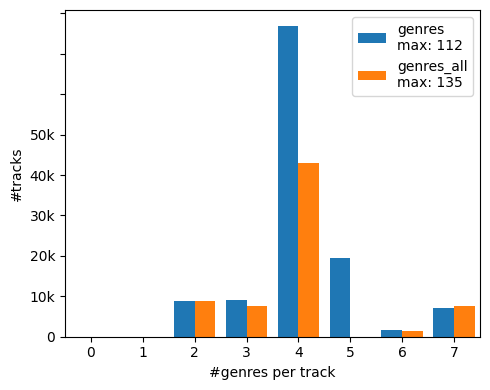

In [26]:
import matplotlib.pyplot as plt
labels = ['genres', 'genres_all']  #, 'genres_top']
d = [tracks['track', label].map(len) for label in labels]
labels = ['{}\nmax: {}'.format(label, d1.max()) for label, d1 in zip(labels, d)]

for l, d1 in zip(labels, d):
    print('{} per track: from {} to {} tags'.format(l, d1.min(), d1.max()))
print('#tracks without genre: {}'.format((tracks['track', 'genres'].map(len) == 0).sum()))

MAX = 9
fig, ax = plt.subplots(figsize=(5, 4))
ax.hist(d, bins=np.arange(MAX)-0.5, label=labels)
ax.set_xlabel('#genres per track')
ax.set_ylabel('#tracks')
ax.set_xlim(-0.5, MAX-1.5)
ax.set_xticks(range(MAX-1))
ax.set_yticklabels(['0'] + ['{}0k'.format(i) for i in range(1, 6)])
ax.legend(loc='upper right')
fig.tight_layout()
fig.savefig('./genres_per_track.pdf')

In [27]:
from sklearn.preprocessing import MultiLabelBinarizer

enc = MultiLabelBinarizer()
genres_indicator = enc.fit_transform(tracks['track', 'genres'])
genres_names = enc.classes_
genres_names = genres.loc[enc.classes_, 'title'].values
cross_correlation = genres_indicator.T @ genres_indicator
     

np.fill_diagonal(cross_correlation, 0)

plt.figure(figsize=(28, 28))
plt.imshow(np.log(cross_correlation))
plt.yticks(range(len(genres_names)), genres_names);
plt.xticks(range(len(genres_names)), genres_names, rotation=90);
     

cross_correlation = np.tril(cross_correlation, k=-1)
sort = np.argsort(cross_correlation.flatten())

N = 20
indices = np.unravel_index(sort[:-N:-1], cross_correlation.shape)
for i, j in zip(*indices):
    print('{}: {} | {}'.format(cross_correlation[i, j], genres_names[i], genres_names[j]))
     


KeyError: "None of [Index([' ', ',', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '[', ']'], dtype='str', name='genre_id')] are in the [index]"

In [19]:
tracks[('track', 'genres_all')]

track_id
2                      [21]
3                      [21]
5                      [21]
10                     [10]
20        [17, 10, 76, 103]
                ...        
155316             [25, 12]
155317             [25, 12]
155318             [25, 12]
155319             [25, 12]
155320     [169, 10, 12, 9]
Name: (track, genres_all), Length: 106574, dtype: str

,#tracks,parent,title,top_level
genre_id,,,,
1,8693,38,Avant-Garde,38
2,5271,0,International,2
3,1752,0,Blues,3
4,4126,0,Jazz,4
5,4106,0,Classical,5


In [5]:
import pydot

class Genres:

    def __init__(self, genres_df):
        self.df = genres_df

    def create_tree(self, roots, depth=None):

        if type(roots) is not list:
            roots = [roots]
        graph = pydot.Dot(graph_type='digraph', strict=True)

        def create_node(genre_id):
            title = self.df.at[genre_id, 'title']
            ntracks = self.df.at[genre_id, '#tracks']
            # name = self.df.at[genre_id, 'title'] + '\n' + str(genre_id)
            name = '"{}\n{} / {}"'.format(title, genre_id, ntracks)
            return pydot.Node(name)

        def create_tree(root_id, node_p, depth):
            if depth == 0:
                return
            children = self.df[self.df['parent'] == root_id]
            for child in children.iterrows():
                genre_id = child[0]
                node_c = create_node(genre_id)
                graph.add_edge(pydot.Edge(node_p, node_c))
                create_tree(genre_id, node_c,
                            depth-1 if depth is not None else None)

        for root in roots:
            node_p = create_node(root)
            graph.add_node(node_p)
            create_tree(root, node_p, depth)

        return graph

    def find_roots(self):
        roots = []
        for gid, row in self.df.iterrows():
            parent = row['parent']
            title = row['title']
            if parent == 0:
                roots.append(gid)
            elif parent not in self.df.index:
                msg = '{} ({}) has parent {} which is missing'.format(
                        gid, title, parent)
                raise RuntimeError(msg)
        return roots


In [6]:
import IPython.display as ipd

g = Genres(genres)
graph = g.create_tree([25, 31], 1)
ipd.Image(graph.create_png())
    

graph = g.create_tree(14)
graph.write_pdf('./genre_hierarchy.pdf');

roots = g.find_roots()
print('{} roots'.format(len(roots)))
graph = g.create_tree(roots)
graph.write_pdf('./genre_hierarchy.pdf');

16 roots


In [8]:
len(graph.get_nodes())

16